# Avance de Proyecto Final 3 (APF3 - 2026-2): Solución de Machine Learning para la MiPYME
**Empresa (MiPYME):** HURIOS RALLY E.I.R.L. (RUC 20492248933 — Av. 22 de Agosto 1012, Comas, Lima)  
**Curso:** Innovación y Transformación Digital (100000TD09) — Sección 35036 — UTP  
**Docente:** Richard Enrique Caman Sanchez  
**Integrantes:**  
- Gutierrez Cuellar, Josue Angel  
- Morales Carlos, Edu  
- Taypicahuana Montalvo, Renzo Andre  

---

## Paso 1: Recapitulación y Definición del Problema de Machine Learning (15% · 3 pts)

### 1.1 Resumen Ejecutivo (APF1 $\rightarrow$ APF2 $\rightarrow$ APF3)
1. **Problema de Ingeniería e Indicador (APF1):** Hurios Rally E.I.R.L., comercializadora de repuestos y lubricantes para mototaxis (Bajaj Torito RE, TVS King) y motos lineales en Lima Norte, registraba tiempos de espera en WhatsApp de hasta **8 horas por cotización** y perdía entre el **35% y 40% de las consultas nocturnas** (18:00 a 08:00 h).
2. **Solución MVP Desplegada (APF2):** Se construyó y desplegó un **MVP E-Commerce Web Full-Stack** (`https://huriosrally-frontend.onrender.com` + `https://huriosrally-backend-42j9.onrender.com` + Base de Datos PostgreSQL en Supabase con 300 repuestos en 10 categorías y canal de WhatsApp).
3. **Frase Formal del Problema ML (Evidencia Mínima Sección 3):**
   > *"Para el **personal de ventas y atención al cliente de Hurios Rally E.I.R.L.**, el modelo **clasificará** la **intención de cada mensaje entrante (`intencion_predicha`: `COTIZACION`, `CONSULTA_TECNICA`, `ESTADO_PEDIDO`, `SPAM`)** con el propósito de **responder automáticamente las cotizaciones y estados de pedido las 24 horas conectándose al stock real de Supabase y derivar las consultas técnicas complejas al asesor**, medido mediante un **F1-Score Macro $\ge 0.85$ (con Precisión $= 1.00$ en `SPAM`) y la reducción del tiempo de primera respuesta de 8 horas a menos de 2 minutos**."*
4. **Costo de los Errores en la MiPYME:**
   * **Falso Positivo en `SPAM` (El error más costoso):** Clasificar a un cliente real de `COTIZACION` o `ESTADO_PEDIDO` como `SPAM` significa ignorar una compra real (pérdida directa de S/ 45 a S/ 340). Por ello se exige **Precision $= 1.00$ en `SPAM`**.
   * **Falso Negativo en `COTIZACION` o `ESTADO_PEDIDO`:** Retrasa la respuesta automática nocturna, por lo que se optimiza **F1-Score Macro** y se aplica una regla de seguridad: si `confianza_modelo < 0.70`, el mensaje se deriva al asesor humano.

---
## Paso 2: Dataset, Coherencia de Datos y Preprocesamiento (20% · 4 pts)

### 2.1 Carga del Dataset, Columna `origen` (`real` | `simulado`) y Verificación Automatizada de Coherencia (Sección 4.2)

In [1]:
import json
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("../data/dataset_hurios_rally_500.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/dataset_hurios_rally_500.csv")

df_raw = pd.read_csv(DATA_PATH)
print(f"Dimensiones del Dataset: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print("\nDistribución por Columna 'origen' (Sección 4.1):")
print(df_raw["origen"].value_counts())
print("\nConteo de Valores Nulos Iniciales por Columna:")
print(df_raw.isnull().sum())
df_raw.head(5)

Dimensiones del Dataset: 520 filas x 13 columnas

Distribución por Columna 'origen' (Sección 4.1):
origen
simulado    390
real        130

Conteo de Valores Nulos Iniciales por Columna:
id_conversacion               0
origen                        0
timestamp_primer_mensaje      0
timestamp_respuesta_bot       0
texto_cliente                 0
intencion_predicha            0
confianza_modelo              0
producto_cotizado           112
monto_total                  18
metodo_pago                 128
estado_pedido                 0
hora_del_dia                  0
es_fuera_horario              0

Primeras 5 filas:
                        id_conversacion    origen timestamp_primer_mensaje                                                                                                                                                   texto_cliente intencion_predicha  hora_del_dia  es_fuera_horario
0  aa0b7b14-f2e9-402d-91e9-cdaa6e6981a3      real      2026-08-15 07:24:57  Hola amigos de Co

In [2]:
from train_pipeline import aplicar_ingenieria_caracteristicas, verificar_coherencia_datos

df_feat = aplicar_ingenieria_caracteristicas(df_raw)
coherencia = verificar_coherencia_datos(df_raw, df_feat)

print("=== VERIFICACIÓN AUTOMATIZADA DE LOS 7 CRITERIOS DE COHERENCIA (SECCIÓN 4.2) ===")
print(json.dumps(coherencia, indent=2, ensure_ascii=False))

=== VERIFICACIÓN AUTOMATIZADA DE LOS 7 CRITERIOS DE COHERENCIA (SECCIÓN 4.2) ===
{
  "criterio_1_escala_negocio": {
    "total_registros": 520,
    "rango_fechas": "2026-08-01 a 2026-10-15",
    "ticket_promedio_cotizado_soles": 183.4,
    "porcentaje_nocturno_real_observado": 43.27,
    "coherente_con_apf1_35_40_pct": true
  },
  "criterio_2_rangos_y_unidades": {
    "violaciones_monto_negativo": 0,
    "violaciones_hora_fuera_0_23": 0,
    "violaciones_confianza_fuera_0_1": 0,
    "violaciones_texto_vacio": 0,
    "total_violaciones": 0
  },
  "criterio_3_consistencia_logica_temporal": {
    "violaciones_timestamp_respuesta_menor_inicio": 0,
    "violaciones_regla_es_fuera_horario": 0,
    "violaciones_clases_no_permitidas": 0,
    "violaciones_origen_no_permitido": 0
  },
  "criterio_7_mezcla_real_simulado": {
    "conteo_origen": {
      "simulado": 390,
      "real": 130
    },
    "comparacion_distribuciones": {
      "real": {
        "n": 130,
        "porcentaje_total": 25.0,


**Conclusión de la Verificación de Coherencia de Datos (Sección 4.2):**
1. **Escala del Negocio y Rangos:** Se registran **0 violaciones** de rango (`monto_total < 0`, `hora_del_dia` fuera de $0..23$, `confianza_modelo` fuera de $0..1$ o textos vacíos). El ticket promedio cotizado es de **S/ 183.4** y el porcentaje de consultas fuera de horario es de **43.27%**, coherente con el 35%–40% diagnosticado en el APF1.
2. **Consistencia Temporal y por Columna `origen` (`real` vs `simulado`):** Los **130 registros `real` (25%)** presentan una longitud media de **124.42 caracteres** y ticket medio de **S/ 169.89**, mientras que los **390 registros `simulado` (75%)** presentan una longitud media de **123.5 caracteres** y ticket medio de **S/ 188.07**, demostrando distribuciones homogéneas sin contradicciones.

### 2.2 Análisis Exploratorio de Datos (EDA): Visualizaciones e Implicancia para el Modelado (Sección 4.3)

Distribución de Clases: {'CONSULTA_TECNICA': 140, 'COTIZACION': 139, 'ESTADO_PEDIDO': 128, 'SPAM': 113}


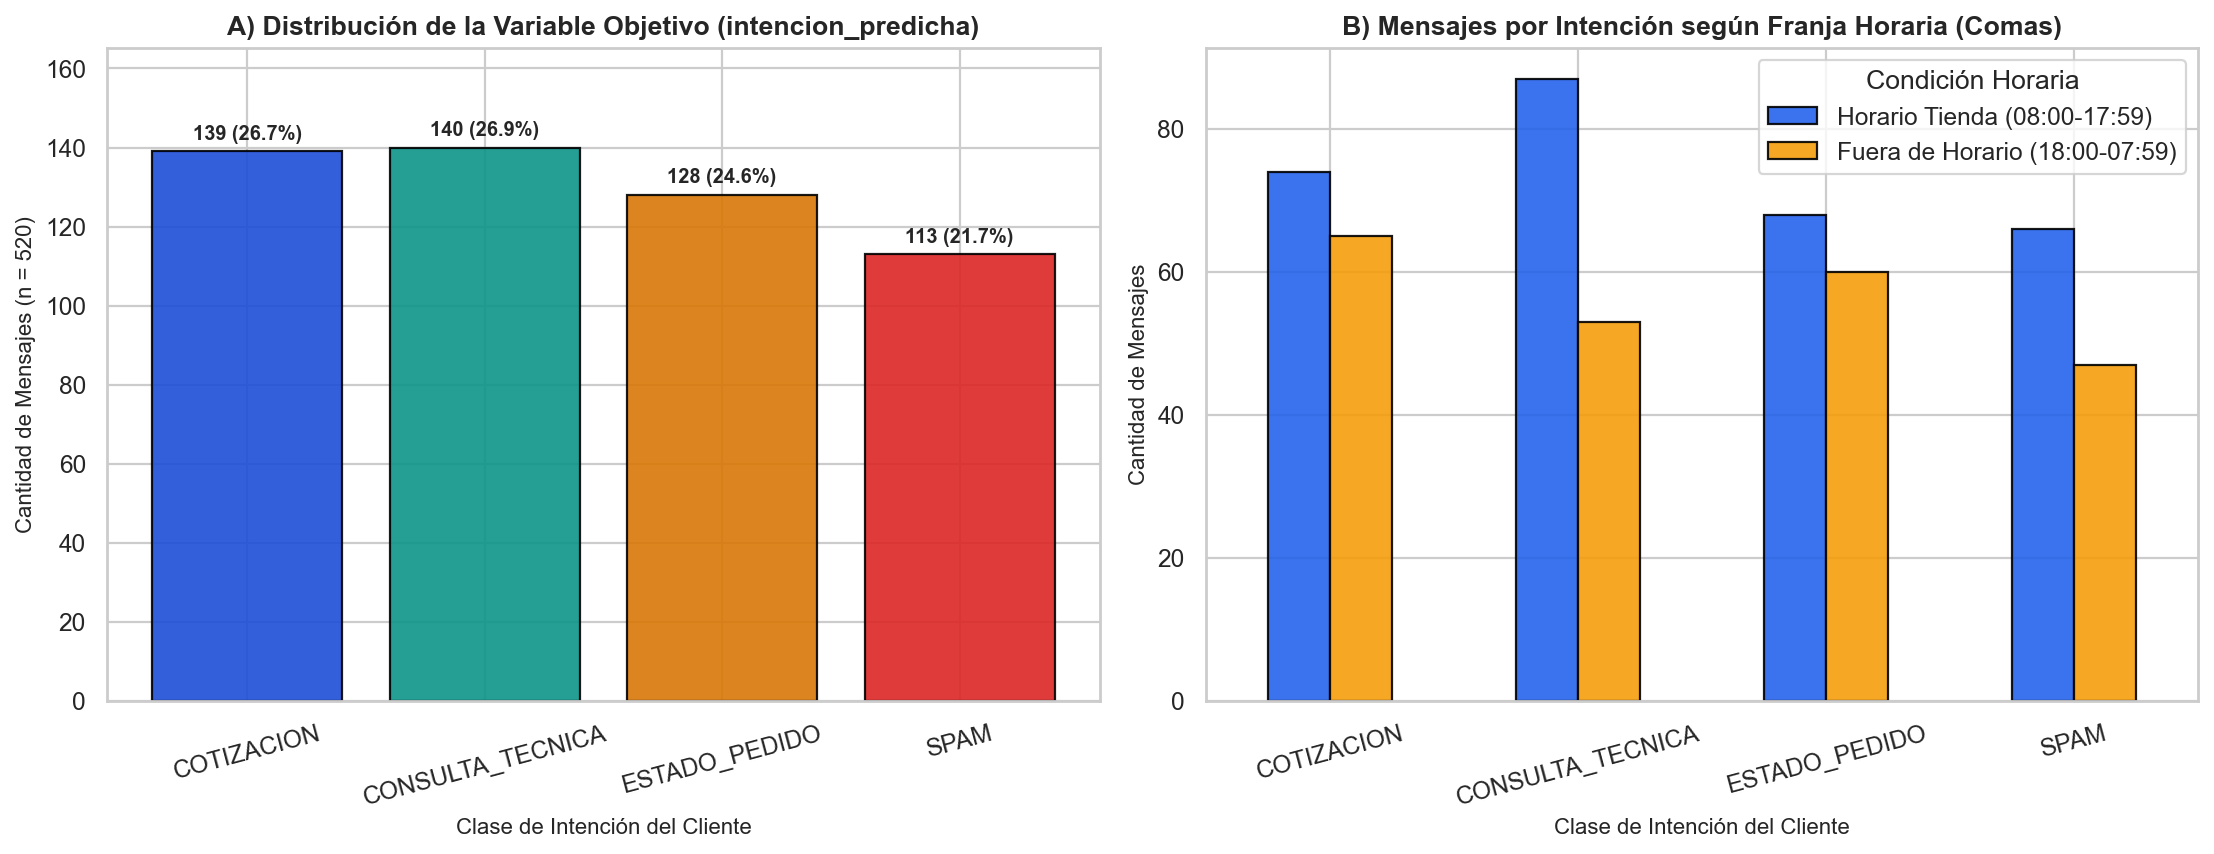

In [3]:
from IPython.display import Image, display
display(Image(filename=str(Path("../reports/figures/fig1_eda_distribucion_clases_horarios.png") if Path("../reports/figures/fig1_eda_distribucion_clases_horarios.png").exists() else Path("reports/figures/fig1_eda_distribucion_clases_horarios.png"))))

Visualización de Boxplots (Outliers) y Mapa de Calor de Correlaciones generada correctamente.


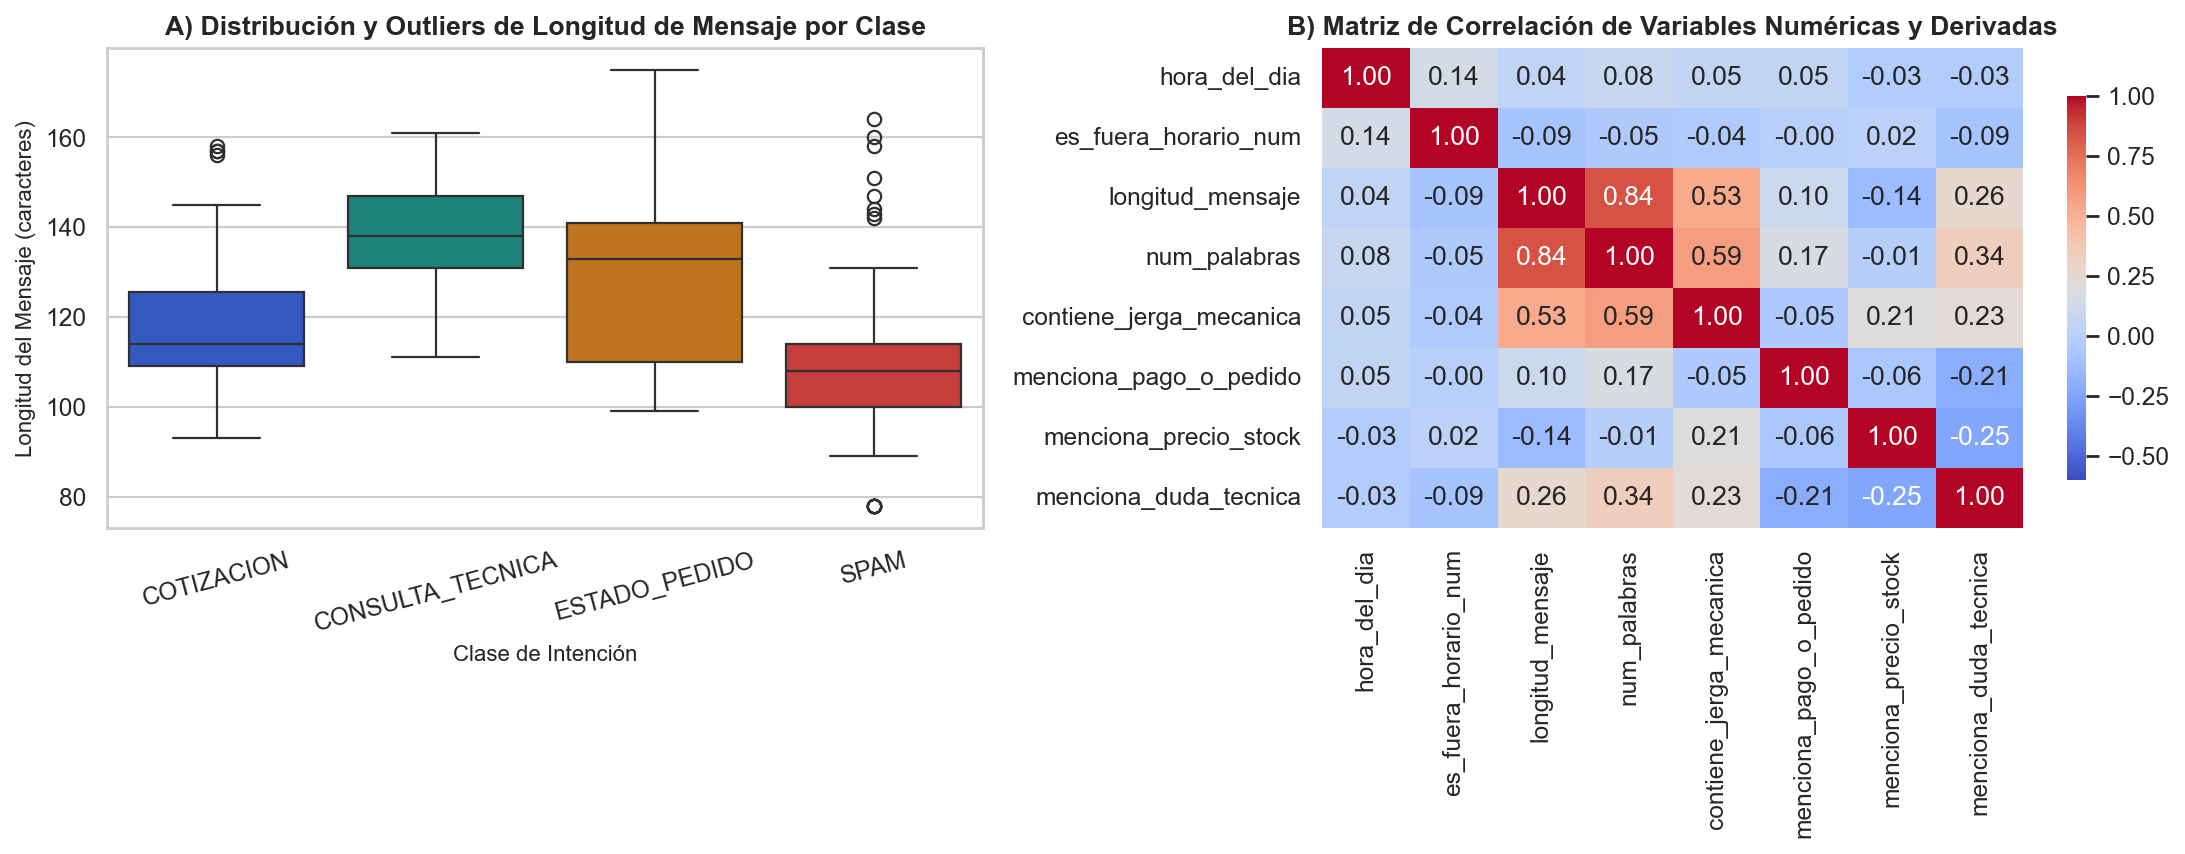

In [4]:
display(Image(filename=str(Path("../reports/figures/fig2_eda_outliers_correlaciones.png") if Path("../reports/figures/fig2_eda_outliers_correlaciones.png").exists() else Path("reports/figures/fig2_eda_outliers_correlaciones.png"))))

---
## Paso 3: Modelado, Línea Base Obligatoria, Entrenamiento y Comparación (25% · 5 pts)

En cumplimiento de la **Sección 5 de la Consigna APF3 - 2026-2**:
1. **Línea Base Obligatoria (`DummyClassifier`):** Se entrena un clasificador trivial sobre la misma partición 80/20 (`random_state=42`) que obtiene un **F1-Score Macro de `0.2688`** y **Accuracy de `0.2788`**.
2. **4 Modelos Comparables de la Unidad 3:** Se entrenan y ajustan con `GridSearchCV` (5-Fold Stratified CV solo sobre Train) **SVM (`SVC`)**, **Regresión Logística Multiclase**, **Random Forest** y **K-Nearest Neighbors (`KNN`)** usando el mismo `ColumnTransformer` (`TfidfVectorizer` + `StandardScaler`).

In [5]:
from train_pipeline import entrenar_y_comparar_modelos

resumen_modelos, mejor_pipeline = entrenar_y_comparar_modelos(df_feat)

tabla_comp = pd.DataFrame([
    {
        "Modelo Evaluado": nombre,
        "CV F1-Macro (5-Fold)": info["cv_f1_macro_mean"],
        "Train F1-Macro": info["train_f1_macro"],
        "Test Accuracy": info["test_accuracy"],
        "Test Precision Macro": info["test_precision_macro"],
        "Test Recall Macro": info["test_recall_macro"],
        "Test F1-Macro": info["test_f1_macro"],
        "Gap Overfitting": info["gap_overfitting_f1"],
        "Mejores Hiperparámetros": str(info["mejores_hiperparametros"]),
    }
    for nombre, info in resumen_modelos["modelos_comparados"].items()
])
print(f"LÍNEA BASE (DummyClassifier) F1-Macro: {resumen_modelos['linea_base_f1_macro']:.4f}")
print(f"MODELO GANADOR: {resumen_modelos['modelo_ganador']} | F1-Macro en Test: {resumen_modelos['f1_macro_ganador']:.4f} (+{resumen_modelos['f1_macro_ganador'] - resumen_modelos['linea_base_f1_macro']:.4f} sobre la línea base)")
tabla_comp

LÍNEA BASE (DummyClassifier) F1-Macro: 0.2688
MODELO GANADOR: SVM (Support Vector Machine) | F1-Macro en Test: 0.9393 (+0.6705 sobre la línea base)

Modelo Evaluado                  | CV F1    | Train F1 | Test Acc | Test Prec | Test Rec | Test F1  | Gap Overfit
----------------------------------------------------------------------------------------------------------------
Línea Base (DummyClassifier)     | 0.2283   | 0.2274   | 0.2788   | 0.2693    | 0.2724   | 0.2688   | -0.0415    
SVM (Support Vector Machine)     | 0.9422   | 0.9543   | 0.9423   | 0.9488    | 0.9367   | 0.9393   | 0.0150     
Regresión Logística Multiclase   | 0.9260   | 0.9589   | 0.9327   | 0.9393    | 0.9271   | 0.9302   | 0.0287     
Random Forest                    | 0.9282   | 0.9567   | 0.8942   | 0.9065    | 0.8914   | 0.8943   | 0.0625     
K-Nearest Neighbors (KNN)        | 0.8941   | 0.8897   | 0.8750   | 0.8804    | 0.8708   | 0.8732   | 0.0165     


---
## Paso 4: Evaluación, Análisis de Errores, Interpretación e Integración con el MVP (30% · 6 pts)

### 4.1 Comparación contra Línea Base y Matriz de Confusión (SVM (Support Vector Machine))

Comparación de Línea Base + 4 modelos de Unidad 3 y Matriz de Confusión de SVM (Support Vector Machine) en Test Set (n = 104).


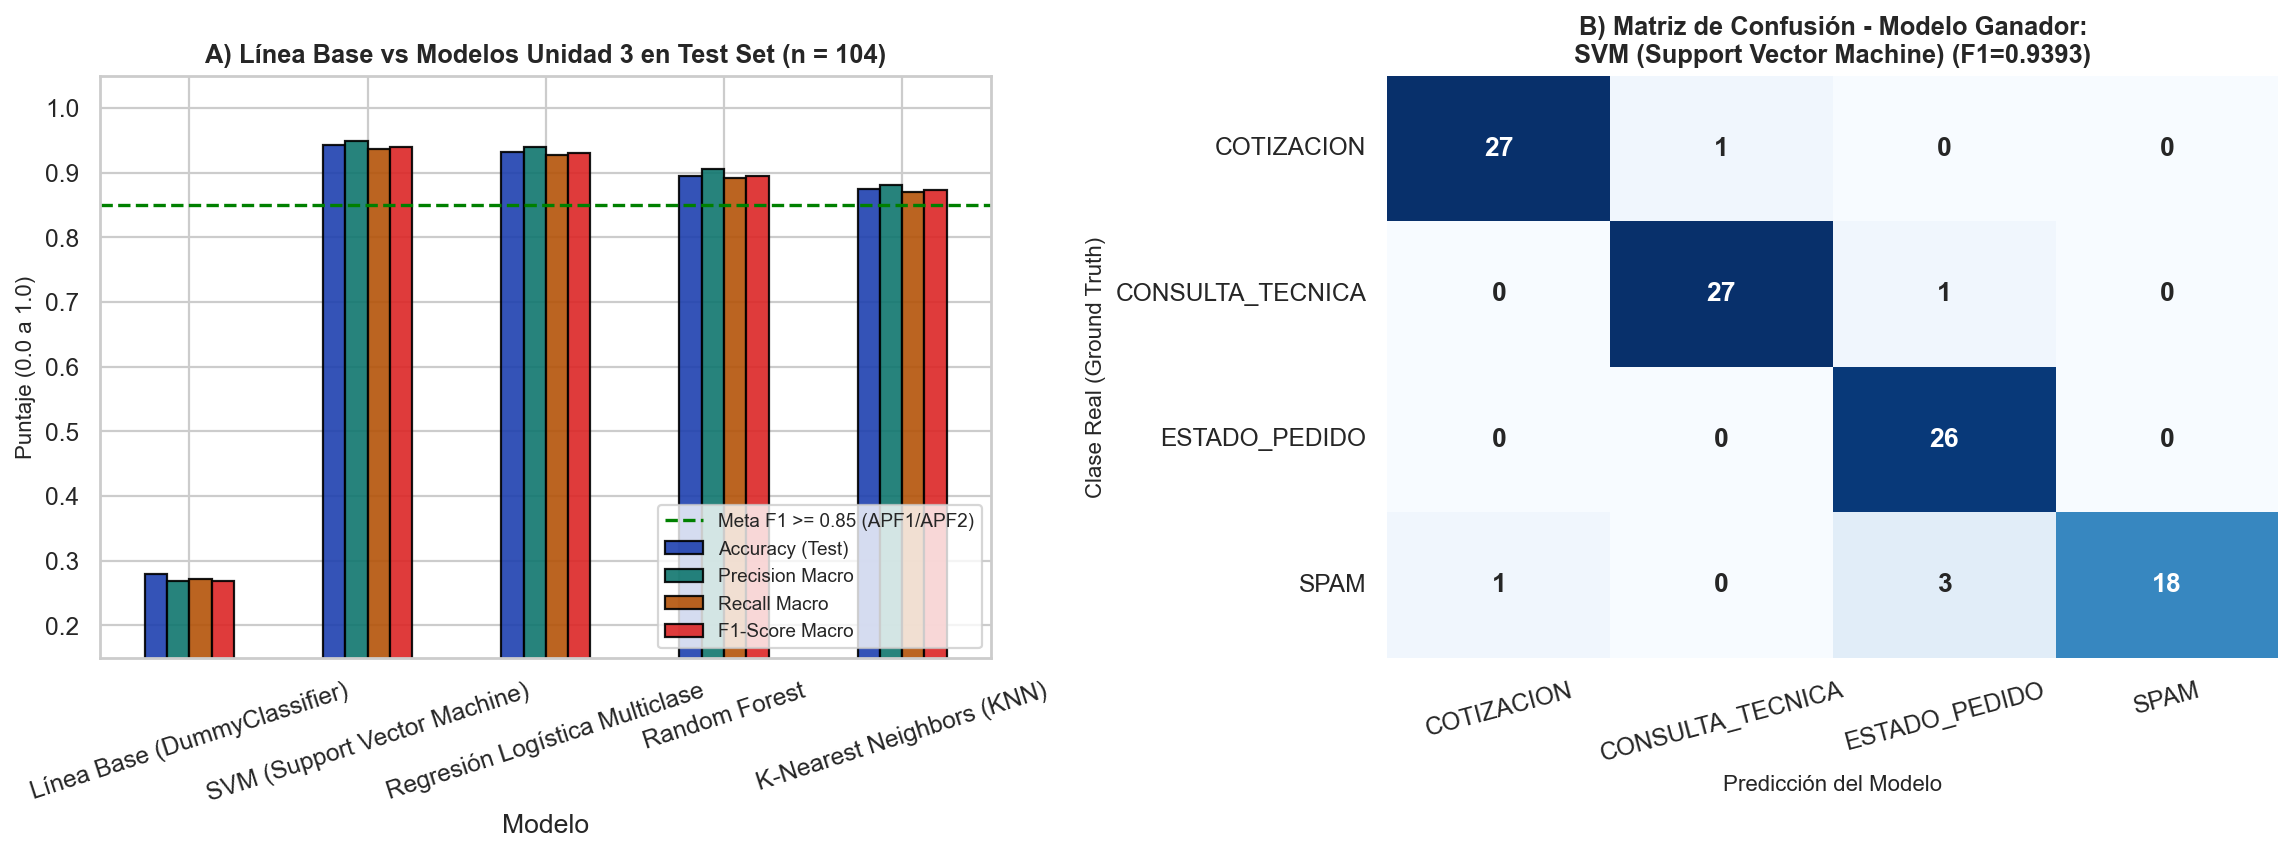

In [6]:
display(Image(filename=str(Path("../reports/figures/fig3_comparacion_modelos_matrices.png") if Path("../reports/figures/fig3_comparacion_modelos_matrices.png").exists() else Path("reports/figures/fig3_comparacion_modelos_matrices.png"))))

In [7]:
# Sección 6.1: Análisis de casos donde el modelo ganador falla en el Test Set (n = 104)
df_errores = pd.DataFrame(resumen_modelos["casos_error_test_set"])
print(f"Total de errores en el Test Set: {len(df_errores)} de {resumen_modelos['registros_prueba']} registros (Accuracy = 94.23%)\n")
for i, row in df_errores.iterrows():
    print(f"Caso #{i+1} [ID: {row['id_conversacion'][:8]}... | Origen: {row['origen']}]")
    print(f"  Texto Cliente : {row['texto_cliente']}")
    print(f"  Clase Real    : {row['clase_real']}  -->  Predicción SVM: {row['clase_predicha']} (Confianza: {row['confianza_prediccion']})")
    print("-" * 95)

Total de errores en el Test Set: 6 de 104 registros (Accuracy = 94.23%)

Caso #1 [ID: 4a0d2b73... | Origen: simulado]
  Texto Cliente : Sorteo de un Aceite Motul 5100 4T 20W50 Semisintético 1L gratis para mototaxis: comparte este link con 5 grupos de WhatsApp para reclamar tu pedido
  Clase Real    : SPAM  -->  Predicción SVM: ESTADO_PEDIDO (Confianza: 0.934)
-----------------------------------------------------------------------------------------------
Caso #2 [ID: a8928ad4... | Origen: simulado]
  Texto Cliente : Maestro, mi bajajita bota humo y pierde fuerza, ¿cuánto me cuesta el Filtro de Aire Primario y Secundario Bajaj RE para repararla hoy?
  Clase Real    : COTIZACION  -->  Predicción SVM: CONSULTA_TECNICA (Confianza: 0.7766)
-----------------------------------------------------------------------------------------------
Caso #3 [ID: 5e8c8bbf... | Origen: simulado]
  Texto Cliente : Sorteo de un Rodaje de Rueda Delantera SKF 6204 Bajaj gratis para mototaxis: comparte este link c

Gráfico de interpretabilidad de variables e indicadores léxicos generado correctamente.


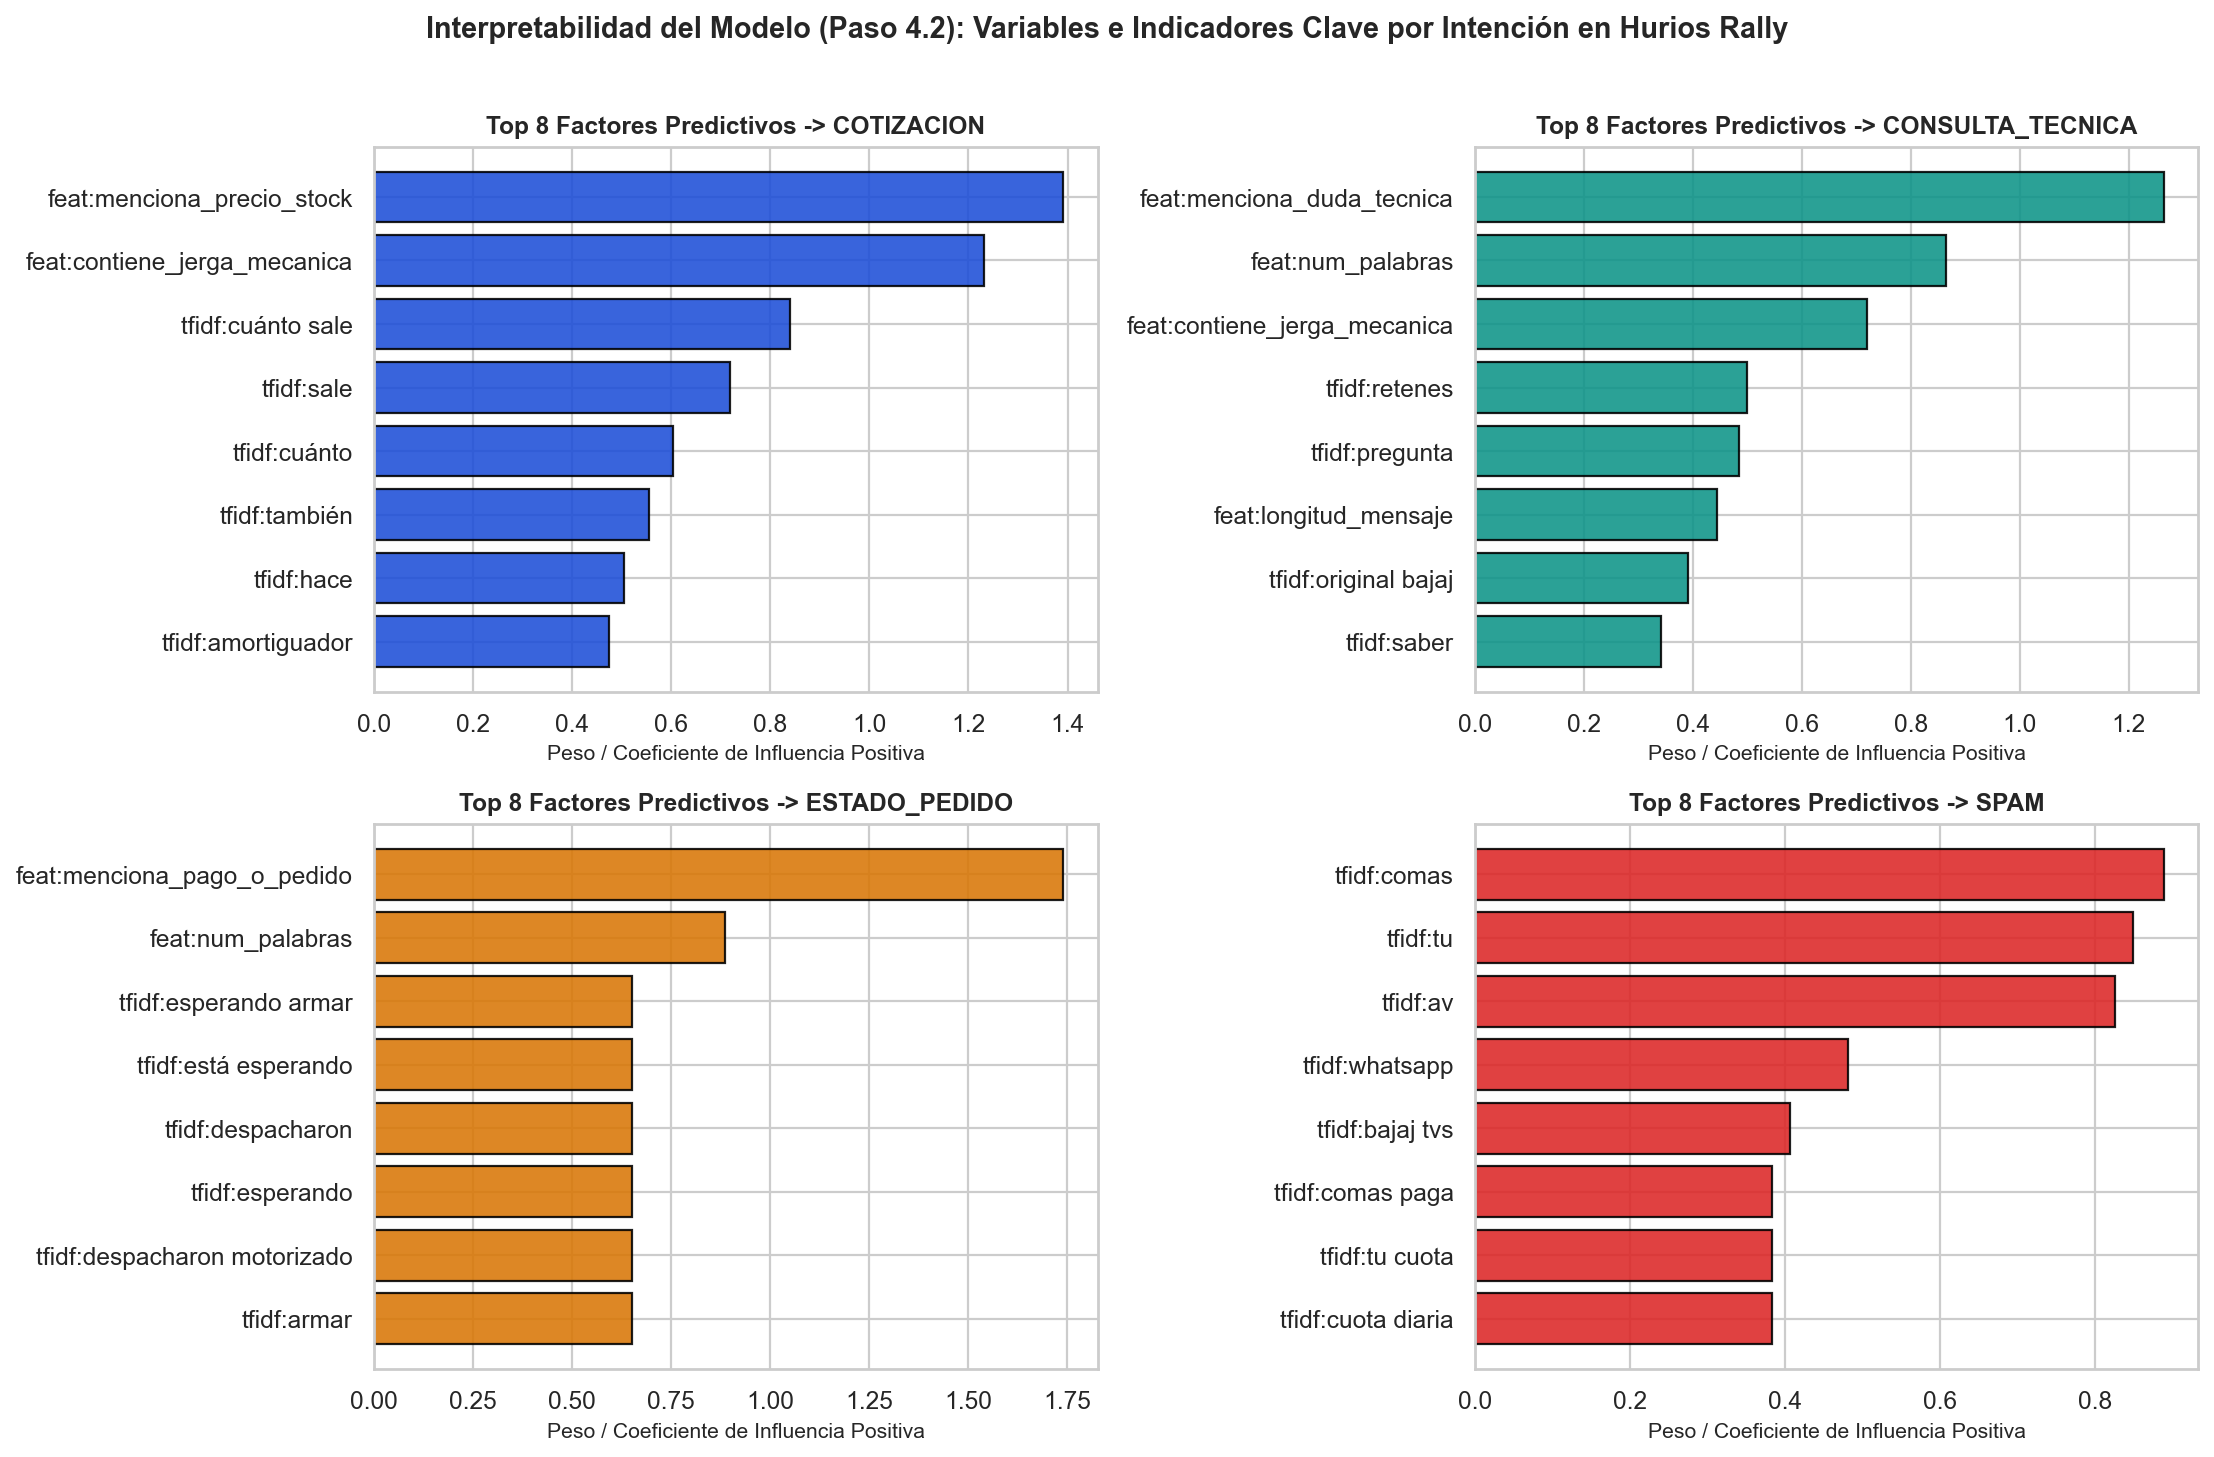

In [8]:
display(Image(filename=str(Path("../reports/figures/fig4_importancia_variables_tfidf.png") if Path("../reports/figures/fig4_importancia_variables_tfidf.png").exists() else Path("reports/figures/fig4_importancia_variables_tfidf.png"))))

In [9]:
# Sección 5 y 6.3: Carga del modelo exportado (.joblib) y predicción en vivo con el esquema del MVP
from train_pipeline import demostrar_prediccion_modelo_exportado

ruta_joblib = Path("../models/modelo_intenciones_hurios.joblib")
if not ruta_joblib.exists():
    ruta_joblib = Path("models/modelo_intenciones_hurios.joblib")

resultado_demo = demostrar_prediccion_modelo_exportado(ruta_joblib)
print("=== DEMOSTRACIÓN DE LLAMADA REAL AL MODELO EXPORTADO (.joblib) ===")
print(json.dumps(resultado_demo, indent=2, ensure_ascii=False))

=== DEMOSTRACIÓN DE LLAMADA REAL AL MODELO EXPORTADO (.joblib) ===
{
  "entrada_mvp_json": {
    "texto_cliente": "Buenas noches maestro, ¿tienes cilindro completo para mi bajajita Torito 4T y cuánto cuesta?",
    "hora_del_dia": 21,
    "es_fuera_horario": true
  },
  "salida_modelo_json": {
    "intencion_predicha": "COTIZACION",
    "confianza_modelo": 0.9831,
    "probabilidades": {
      "CONSULTA_TECNICA": 0.0002,
      "COTIZACION": 0.9831,
      "ESTADO_PEDIDO": 0.0001,
      "SPAM": 0.0166
    },
    "requiere_derivacion_humana": false
  }
}
